# P5: moons → swiss roll

Bridge matching with $x_t = (1 - t)\,x_0 + t\,x_1 + \sqrt{\varepsilon\,t(1 - t)}\,z$ and target $(x_1 - x_t)/(1 - t)$, sampled with $dX = v\,dt + \sqrt{\varepsilon}\,dW$. At $\varepsilon = 0$ this is the Rectified Flow of P3.

In [1]:
import warnings

warnings.filterwarnings("ignore", category=SyntaxWarning)

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_swiss_roll

np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(2)

In [2]:
def sample_moons(n, noise=0.05, scale=2.0):
    X, _ = make_moons(n_samples=n, noise=noise)
    return (X - X.mean(axis=0)) * scale

In [3]:
def sample_swiss_roll(n, noise=0.5, scale=0.3):
    X, _ = make_swiss_roll(n_samples=n, noise=noise)
    X = X[:, [0, 2]]
    return (X - X.mean(axis=0)) * scale

In [4]:
moons = torch.tensor(sample_moons(20000), dtype=torch.float32)
swiss = torch.tensor(sample_swiss_roll(20000), dtype=torch.float32)
z0 = torch.tensor(sample_moons(10000), dtype=torch.float32)
z1 = torch.tensor(sample_swiss_roll(10000), dtype=torch.float32)

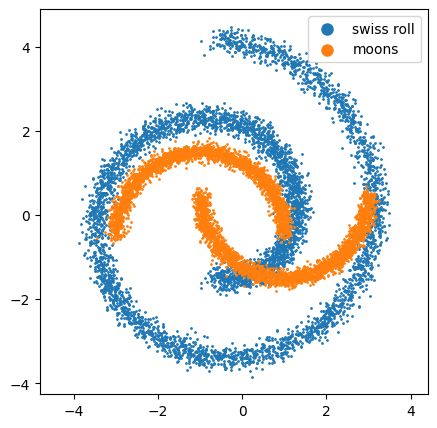

In [5]:
plt.figure(figsize=(5, 5))
plt.scatter(*swiss[:5000].T, s=1, label="swiss roll")
plt.scatter(*moons[:5000].T, s=1, label="moons")
plt.legend(markerscale=8)
plt.axis("equal");

In [6]:
import sys

sys.path.append("..")
from p0.models import MLP


def train(x0_data, x1_data, eps=0.0, n_iters=5000, lr=1e-3, rf_target=False):
    model = MLP()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, n_iters)
    losses = []
    B = 512
    for _ in range(n_iters):
        batch_idx = torch.randint(0, len(x1_data), (B,))
        x0 = x0_data[batch_idx]
        x1 = x1_data[batch_idx]
        t = torch.rand(B, 1) * (1 - 1e-3)
        #        t = torch.rand(B, 1)
        z = torch.randn_like(x0)
        xt = x0 * (1 - t) + x1 * t + (eps * t * (1 - t)).sqrt() * z
        target = x1 - x0 if rf_target else (x1 - xt) / (1 - t)
        pred = model(xt, t)
        loss = F.mse_loss(pred, target)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        losses.append(loss.item())
    return (model.eval(), losses)

In [7]:
from p0.integrators import euler_maruyama

ts = torch.linspace(0, 1, 101)


def generate(model, x0, eps=0.0, return_traj=True):
    g = eps**0.5 if eps > 0 else None
    with torch.no_grad():
        return euler_maruyama(model, g, x0, ts, return_traj=return_traj)

In [8]:
def plot_trajs(ax, traj, title="", n_show=200):
    traj = traj.numpy()
    ax.plot(
        traj[:, :n_show, 0], traj[:, :n_show, 1], linewidth=0.5, alpha=0.4, color="gray"
    )
    ax.scatter(
        traj[0, :n_show, 0],
        traj[0, :n_show, 1],
        s=5,
        color="tab:blue",
        zorder=3,
        label="t=0",
    )
    ax.scatter(
        traj[-1, :n_show, 0],
        traj[-1, :n_show, 1],
        s=5,
        color="tab:red",
        zorder=3,
        label="t=1",
    )
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_axis_off()

# Bridge matching, ε ∈ {0, 0.1, 1}

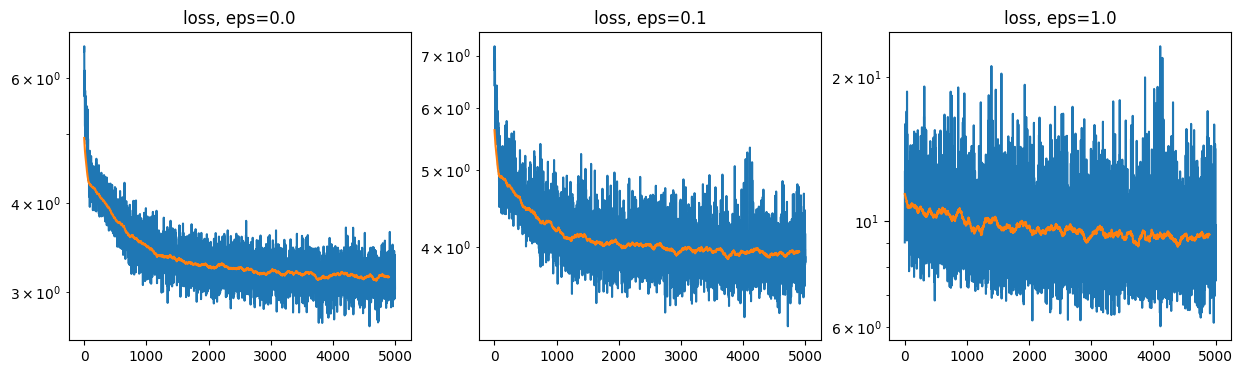

In [9]:
EPS = [0.0, 0.1, 1.0]
models = {}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, eps in zip(axes, EPS):
    torch.manual_seed(0)
    models[eps], losses = train(moons, swiss, eps)
    ax.semilogy(losses)
    ax.semilogy(np.convolve(losses, np.ones(100) / 100, mode="valid"))
    ax.set_title(f"loss, eps={eps}")

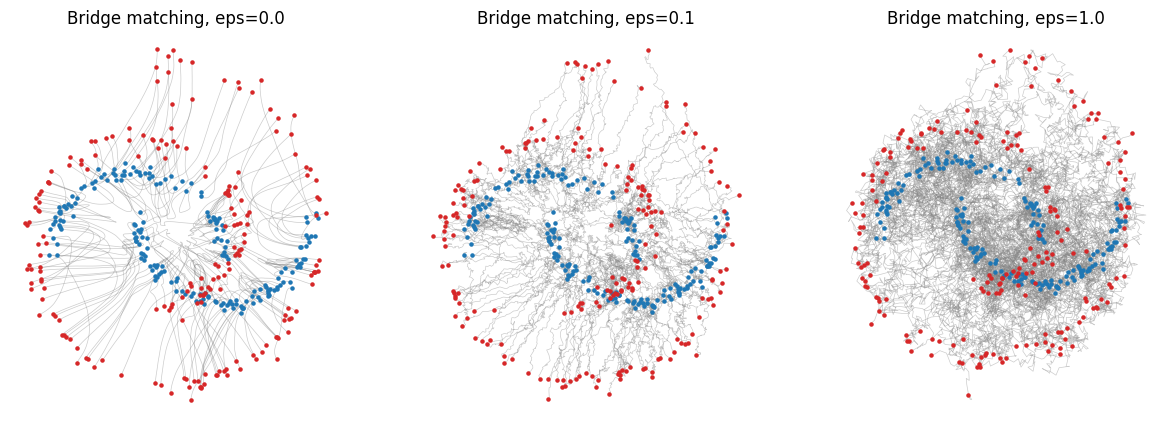

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, eps in zip(axes, EPS):
    torch.manual_seed(0)
    plot_trajs(
        ax, generate(models[eps], z0[:2000], eps), title=f"Bridge matching, eps={eps}"
    )

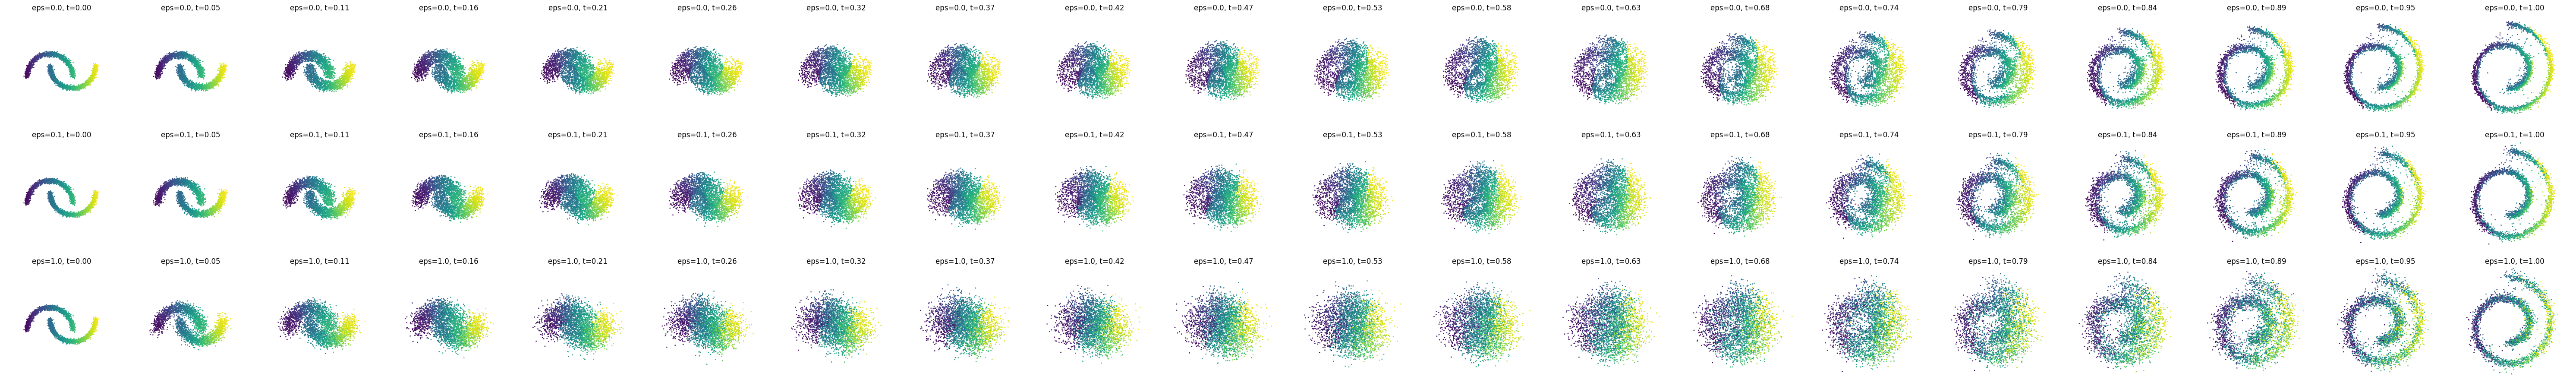

In [11]:
frames = torch.linspace(0, len(ts) - 1, 20).round().long().tolist()

fig, axes = plt.subplots(len(EPS), len(frames), figsize=(3 * len(frames), 3 * len(EPS)))
for i, eps in enumerate(EPS):
    torch.manual_seed(0)
    traj = generate(models[eps], z0[:3000], eps)
    for ax, k in zip(axes[i], frames):
        ax.scatter(*traj[k].T, s=1, c=z0[:3000, 0], cmap="viridis")
        ax.set_title(f"eps={eps}, t={ts[k].item():.2f}")
        ax.set_xlim(-5, 5)
        ax.set_ylim(-5, 5)
        ax.set_aspect("equal")
        ax.set_axis_off()
fig.tight_layout()

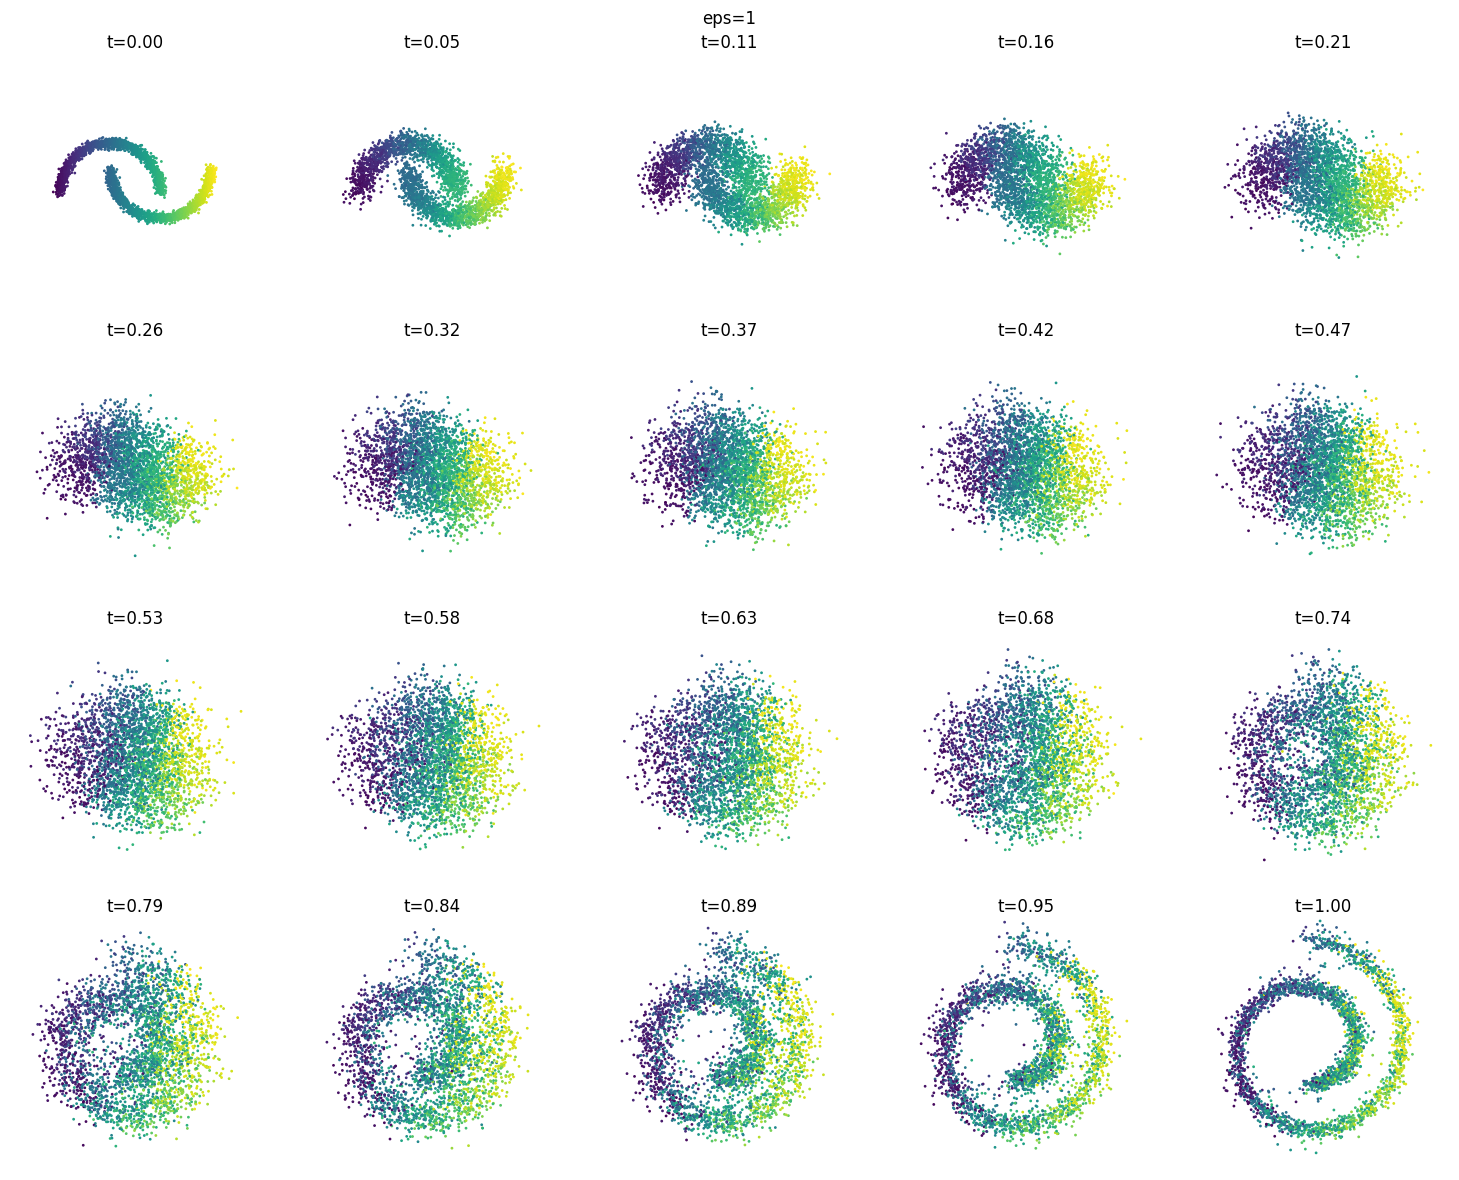

In [12]:
eps = 1
n_frames = 20

torch.manual_seed(0)
model_eps, _ = train(moons, swiss, eps)

torch.manual_seed(0)
traj = generate(model_eps, z0[:3000], eps)
frames = torch.linspace(0, len(ts) - 1, n_frames).round().long().tolist()

fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for ax, k in zip(axes.flat, frames):
    ax.scatter(*traj[k].T, s=1, c=z0[:3000, 0], cmap="viridis")
    ax.set_title(f"t={ts[k].item():.2f}")
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_aspect("equal")
    ax.set_axis_off()
fig.suptitle(f"eps={eps}")
fig.tight_layout()


# ε = 0 vs Rectified Flow

Same seed, target $x_1 - x_0$ as in P3.

In [13]:
torch.manual_seed(0)
model_rf, _ = train(moons, swiss, rf_target=True)

x_bm = generate(models[0.0], z0, return_traj=False)
x_rf = generate(model_rf, z0, return_traj=False)
diff = (x_bm - x_rf).norm(dim=1).mean().item()
path = (x_rf - z0).norm(dim=1).mean().item()
print(f"mean |x1_bm - x1_rf| = {diff:.2e}, mean |x1_rf - x0| = {path:.2f}")

mean |x1_bm - x1_rf| = 2.38e-06, mean |x1_rf - x0| = 1.34


# IMF vs reflow

Every iteration is trained on the coupling $(x_0, X_1)$ generated by the previous model; with $\varepsilon = 0$ this is reflow.

In [14]:
from p0.metrics import sliced_wasserstein, straightness


def nn_dist(x, ref):
    return torch.cdist(x[:5000], ref).min(dim=1).values.mean().item()


def evaluate(model, eps):
    torch.manual_seed(1)
    traj = generate(model, z0, eps)
    x1 = traj[-1]
    return {
        "cost": ((x1 - z0)[:5000] ** 2).sum(dim=1).mean().item(),
        "straightness": straightness(model, traj, ts),
        "sw": sliced_wasserstein(x1, z1),
        "nn": nn_dist(x1, z1),
    }, traj

In [15]:
N_ITERS = 4
results = {eps: [] for eps in EPS}
trajs = {eps: [] for eps in EPS}
imf_models = {eps: [] for eps in EPS}

for eps in EPS:
    torch.manual_seed(0)
    model, x1 = models[eps], swiss
    for k in range(N_ITERS):
        if k > 0:
            x1 = generate(model, moons, eps, return_traj=False)
            model, _ = train(moons, x1, eps)
        res, traj = evaluate(model, eps)
        imf_models[eps].append(model)
        results[eps].append(res)
        trajs[eps].append(traj[:, :200])
        print(
            f"eps={eps}, iter {k + 1}: "
            + ", ".join(f"{name}={v:.4f}" for name, v in res.items())
        )

eps=0.0, iter 1: cost=2.3414, straightness=3.5931, sw=0.0438, nn=0.0255
eps=0.0, iter 2: cost=2.2662, straightness=0.0105, sw=0.0667, nn=0.0518
eps=0.0, iter 3: cost=2.2162, straightness=0.0051, sw=0.0797, nn=0.0652
eps=0.0, iter 4: cost=2.1850, straightness=0.0037, sw=0.0881, nn=0.0731
eps=0.1, iter 1: cost=2.5924, straightness=3.6761, sw=0.0346, nn=0.0254
eps=0.1, iter 2: cost=2.3259, straightness=0.3390, sw=0.0418, nn=0.0334
eps=0.1, iter 3: cost=2.2655, straightness=0.2997, sw=0.0485, nn=0.0378
eps=0.1, iter 4: cost=2.2293, straightness=0.2852, sw=0.0558, nn=0.0451
eps=1.0, iter 1: cost=4.3160, straightness=5.9796, sw=0.0426, nn=0.0317
eps=1.0, iter 2: cost=3.5256, straightness=3.6004, sw=0.0484, nn=0.0410
eps=1.0, iter 3: cost=3.4657, straightness=3.2667, sw=0.0589, nn=0.0527
eps=1.0, iter 4: cost=3.4793, straightness=3.0358, sw=0.0737, nn=0.0669


In [16]:
sw_data = sliced_wasserstein(swiss[:10000], z1)
nn_data = nn_dist(swiss, z1)
print(f"{sw_data=}\n{nn_data=}")

sw_data=0.03524398431181908
nn_data=0.02202972024679184


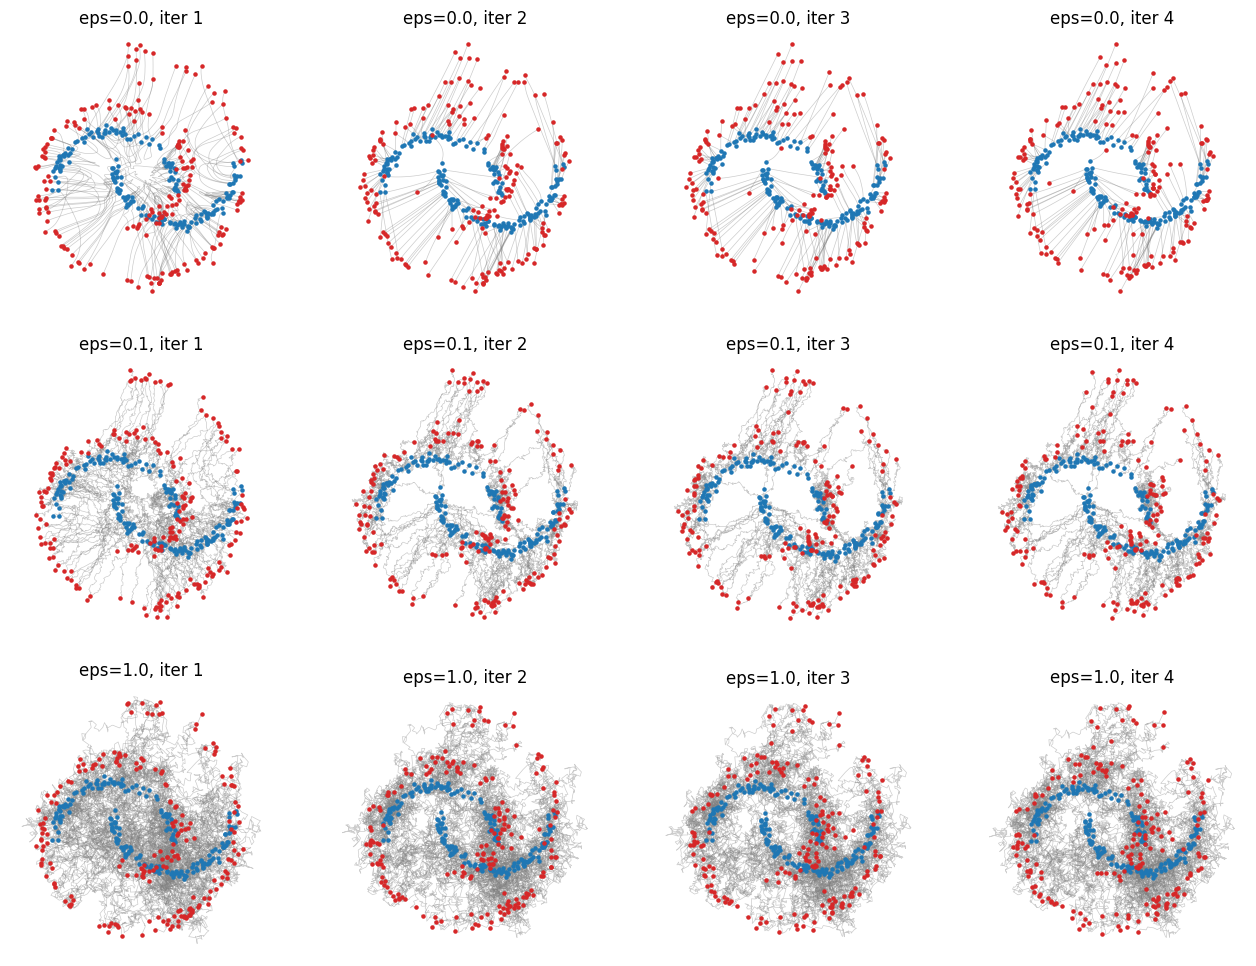

In [17]:
fig, axes = plt.subplots(len(EPS), N_ITERS, figsize=(4 * N_ITERS, 4 * len(EPS)))
for i, eps in enumerate(EPS):
    for k in range(N_ITERS):
        plot_trajs(axes[i, k], trajs[eps][k], title=f"eps={eps}, iter {k + 1}")

# OT, Sinkhorn

Same points as in the `cost` column. The Schrödinger bridge of $dX = \sqrt{\varepsilon}\,dW$ is entropic OT with cost $\|x - y\|^2$ and regularization $2\varepsilon$.

In [18]:
import ot

n_ot = 5000
C = torch.cdist(z0[:n_ot].double(), z1[:n_ot].double()) ** 2
a = torch.full((n_ot,), 1 / n_ot, dtype=torch.float64)

cost_indep = C.mean().item()
cost_ot = (ot.emd(a, a, C, numItermax=1_000_000) * C).sum().item()
cost_sinkhorn = {}
for eps in EPS[1:]:
    P = ot.sinkhorn(
        a, a, C, reg=2 * eps, method="sinkhorn_log", numItermax=20000, stopThr=1e-5
    )
    cost_sinkhorn[eps] = (P * C).sum().item()
print(f"{cost_indep=}\n{cost_ot=}\n{cost_sinkhorn=}")

cost_indep=12.209778552572455
cost_ot=2.0179037089830523
cost_sinkhorn={0.1: 2.1610036780163373, 1.0: 3.293332328382096}


# Results

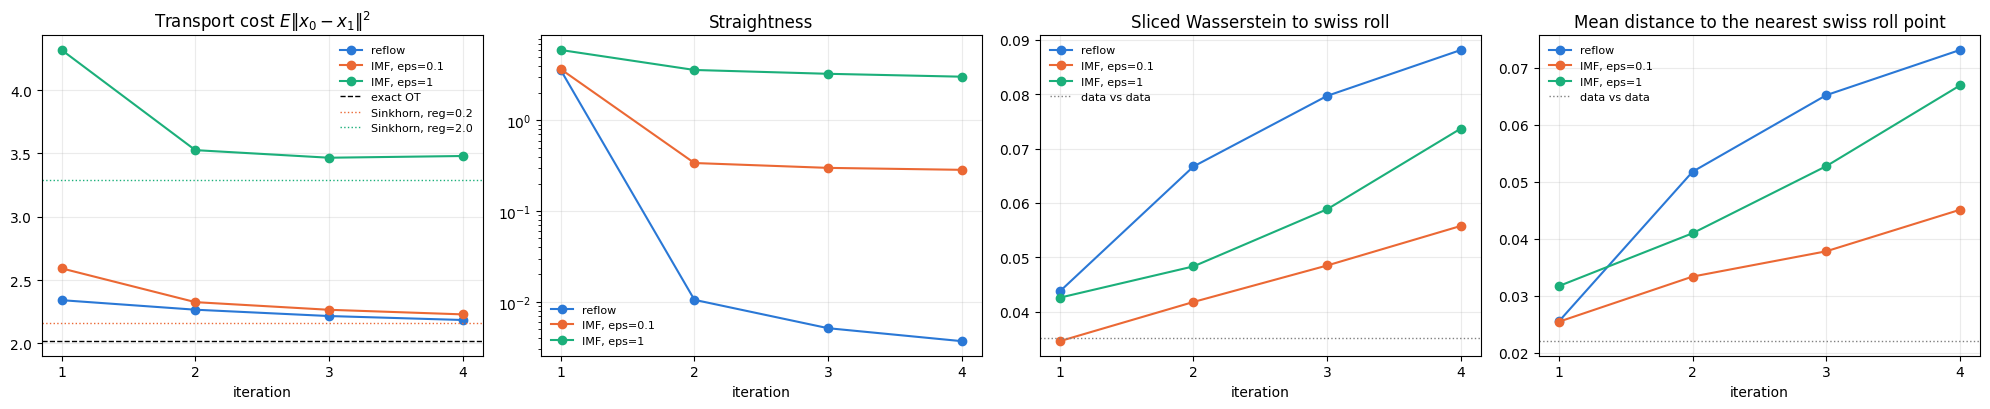

In [19]:
colors = {0.0: "#2a78d6", 0.1: "#eb6834", 1.0: "#1baf7a"}
labels = {0.0: "reflow", 0.1: "IMF, eps=0.1", 1.0: "IMF, eps=1"}
iters = np.arange(1, N_ITERS + 1)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for eps in EPS:
    axes[0].plot(
        iters,
        [r["cost"] for r in results[eps]],
        "o-",
        color=colors[eps],
        label=labels[eps],
    )
    axes[1].semilogy(
        iters,
        [r["straightness"] for r in results[eps]],
        "o-",
        color=colors[eps],
        label=labels[eps],
    )
    axes[2].plot(
        iters,
        [r["sw"] for r in results[eps]],
        "o-",
        color=colors[eps],
        label=labels[eps],
    )
    axes[3].plot(
        iters,
        [r["nn"] for r in results[eps]],
        "o-",
        color=colors[eps],
        label=labels[eps],
    )

axes[0].axhline(cost_ot, color="k", linestyle="--", linewidth=1, label="exact OT")
for eps in EPS[1:]:
    axes[0].axhline(
        cost_sinkhorn[eps],
        color=colors[eps],
        linestyle=":",
        linewidth=1,
        label=f"Sinkhorn, reg={2 * eps}",
    )
axes[2].axhline(sw_data, color="gray", linestyle=":", linewidth=1, label="data vs data")
axes[3].axhline(nn_data, color="gray", linestyle=":", linewidth=1, label="data vs data")

axes[0].set_title("Transport cost $E\\|x_0 - x_1\\|^2$")
axes[1].set_title("Straightness")
axes[2].set_title("Sliced Wasserstein to swiss roll")
axes[3].set_title("Mean distance to the nearest swiss roll point")
for ax in axes:
    ax.set_xlabel("iteration")
    ax.set_xticks(iters)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("moons_to_swiss_roll.png", dpi=140)

# SW and MMD² vs NFE

Every model of every iteration is sampled with 1, 2, 4 and 8 Euler(–Maruyama) steps.

In [20]:
import pandas as pd
from p0.metrics import mmd2

nfes = [1, 2, 4, 8]


def nfe_tables(eps, name):
    rows = [f"{i + 1}-{name}" for i in range(len(imf_models[eps]))]
    g = eps**0.5 if eps > 0 else None
    sw, mmd = [], []
    for model in imf_models[eps]:
        sw.append([])
        mmd.append([])
        for n in nfes:
            torch.manual_seed(1)
            with torch.no_grad():
                x1 = euler_maruyama(model, g, z0, torch.linspace(0, 1, n + 1))
            sw[-1].append(sliced_wasserstein(x1, z1))
            mmd[-1].append(mmd2(x1, z1))

    df_sw = pd.DataFrame(sw, index=rows, columns=[f"NFE={n}" for n in nfes])
    df_mmd = pd.DataFrame(mmd, index=rows, columns=[f"NFE={n}" for n in nfes])
    display(
        df_sw.style.format("{:.4f}")
        .background_gradient(cmap="RdYlGn_r", axis=None)
        .set_caption(f"Sliced Wasserstein, eps={eps}")
    )
    display(
        df_mmd.style.format("{:.4f}")
        .background_gradient(cmap="RdYlGn_r", axis=None)
        .set_caption(f"MMD², eps={eps}")
    )

In [21]:
nfe_tables(0.0, "RF")

,NFE=1,NFE=2,NFE=4,NFE=8
1-RF,1.5887,0.8811,0.6366,0.3364
2-RF,0.1190,0.1058,0.0946,0.0831
3-RF,0.1194,0.1109,0.1026,0.0943
4-RF,0.1196,0.1141,0.1075,0.1007


,NFE=1,NFE=2,NFE=4,NFE=8
1-RF,0.1744,0.0496,0.0225,0.0046
2-RF,0.0000,-0.0000,-0.0001,-0.0001
3-RF,-0.0001,-0.0001,-0.0001,-0.0001
4-RF,-0.0001,-0.0001,-0.0001,-0.0001


In [22]:
nfe_tables(0.1, "IMF")

,NFE=1,NFE=2,NFE=4,NFE=8
1-IMF,1.5134,0.8648,0.5718,0.2849
2-IMF,0.2178,0.1575,0.1033,0.0755
3-IMF,0.1968,0.1436,0.0983,0.0770
4-IMF,0.1947,0.1439,0.1018,0.0811


,NFE=1,NFE=2,NFE=4,NFE=8
1-IMF,0.1650,0.0504,0.0178,0.0034
2-IMF,0.0014,0.0005,0.0001,-0.0000
3-IMF,0.0008,0.0004,0.0001,0.0000
4-IMF,0.0008,0.0004,0.0001,0.0001


In [23]:
nfe_tables(1.0, "IMF")

,NFE=1,NFE=2,NFE=4,NFE=8
1-IMF,1.0361,0.6268,0.3318,0.1677
2-IMF,0.3529,0.2323,0.1521,0.1014
3-IMF,0.2762,0.2034,0.1464,0.1026
4-IMF,0.2708,0.2016,0.1501,0.1098


,NFE=1,NFE=2,NFE=4,NFE=8
1-IMF,0.0846,0.0270,0.0057,0.0008
2-IMF,0.0063,0.0015,0.0002,0.0002
3-IMF,0.0023,0.0005,0.0002,0.0002
4-IMF,0.0020,0.0005,0.0002,0.0003
